In [1]:
from typing import Literal

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
from dtaianomaly.visualization import plot_demarcated_anomalies

from hydraad import HydraAD, TSBADLoader

In [2]:
def load_tsb_ad(
    mode: Literal["multivariate", "univariate"], return_characteristics: bool = False
) -> (pd.DataFrame, pd.DataFrame | None):
    mode_ = "uni" if mode == "univariate" else "multi"
    tsb_ad_raw_ = pd.read_csv(
        f"../results/TSB-AD/{mode_}_mergedTable_VUS-PR.csv", index_col="file"
    )
    tsb_ad_characteristics_cols_ = [
        "ts_len",
        "anomaly_len",
        "num_anomaly",
        "avg_anomaly_len",
        "anomaly_ratio",
        "point_anomaly",
        "seq_anomaly",
    ]
    tsb_ad_characteristics_ = tsb_ad_raw_[tsb_ad_characteristics_cols_]
    tsb_ad_ = tsb_ad_raw_.drop(columns=tsb_ad_characteristics_cols_)
    if return_characteristics:
        return tsb_ad_, tsb_ad_characteristics_
    else:
        return tsb_ad_


def load_results(
    method: str,
    mode: Literal["multivariate", "univariate"],
    return_runtime: bool = False,
) -> pd.DataFrame:
    results = pd.read_csv(
        f"../results/benchmarks/{method}-{mode}.csv", index_col="file"
    )
    results = results.rename(columns={"VolumeUnderPR_TSBAD()": method})
    if return_runtime:
        return results[["Runtime [s]"]]
    else:
        return results[[method]]


def load_with_tsb_ad(
    method: str, mode: Literal["multivariate", "univariate"]
) -> pd.DataFrame:
    tsb_ad_ = load_tsb_ad(mode=mode, return_characteristics=False)
    results_ = (
        load_results(method=method, mode=mode, return_runtime=False)
        .groupby("file")
        .mean()
    )
    return tsb_ad_.join(results_)

In [3]:
def plot_boxplot_variation(
    df, figsize=(14, 5), threshold=0.1, title=None, ax: plt.Axes = None
):
    def get_whisker_stats(group):
        q1 = group.quantile(0.25)
        q3 = group.quantile(0.75)
        iqr = q3 - q1
        # Calculate theoretical whisker limits
        lower_bound = q1 - 1.5 * iqr
        upper_bound = q3 + 1.5 * iqr

        # Whiskers are the min/max data points within those bounds
        actual_min = group[group >= lower_bound].min()
        actual_max = group[group <= upper_bound].max()

        return pd.Series(
            {
                "median": group.median(),
                "w_low": actual_min,
                "w_high": actual_max,
                "whisker_dist": actual_max - actual_min,
            }
        )

    # 1. Calculate whisker-based stats
    stats = df.groupby("file")["HydraAD"].apply(get_whisker_stats).unstack()

    # 2. Sort the index by median performance
    sorted_files = stats.sort_values("median").index.tolist()

    # 3. Create the figure
    if ax is None:
        fig, ax = plt.subplots(figsize=figsize)
    else:
        fig = ax.figure

    sns.boxplot(
        data=df,
        x="file",
        y="HydraAD",
        order=sorted_files,
        ax=ax,
        showfliers=False,
    )

    # 4. Annotate based on threshold
    # Filter datasets where the distance between whiskers exceeds your limit
    if isinstance(threshold, float):
        high_var_stats = stats[stats["whisker_dist"] > threshold]
    elif isinstance(threshold, int):
        high_var_stats = stats.sort_values("whisker_dist", ascending=False).head(
            threshold
        )
    else:
        raise ValueError(
            "Threshold must be either a float (distance) or an int (number of datasets)"
        )

    for filename, row in high_var_stats.iterrows():
        x_pos = sorted_files.index(filename)
        y_val = row["median"]

        ax.annotate(
            f"ID {filename.split('_')[0]}",
            xy=(x_pos, y_val),
            xytext=(15, -35),  # Staggered offset
            textcoords="offset points",
            arrowprops=dict(
                arrowstyle="->", color="red", connectionstyle="arc3,rad=-.2"
            ),
            fontsize=8,
            bbox=dict(boxstyle="round,pad=0.2", fc="white", ec="gray", alpha=0.8),
        )

    ax.set_title(
        (title or "")
        + f"({high_var_stats.shape[0]} time series with whisker distance > {threshold})",
        fontsize=16,
    )
    ax.set_xlabel("Time series, sorted according to median VUS-PR", fontsize=12)
    ax.set_ylabel("VUS-PR", fontsize=12)
    ax.grid(True, linestyle="--", alpha=0.4)
    ax.set_xticks([])

    fig.tight_layout()
    return fig, stats

In [4]:
def repeated_hydraad_evaluation(instance, n_runs=100, **kwargs):
    try:
        data = TSBADLoader(f"../data/TSB-AD-U/{instance.name}").load()
    except ValueError:
        data = TSBADLoader(f"../data/TSB-AD-M/{instance.name}").load()
    X_train = data.X_train
    X_test = data.X_test
    y_test = data.y_test

    print(X_test.shape)

    predictions = np.array(
        [
            HydraAD("fft", seed=seed, **kwargs).fit(X_train).decision_function(X_test)
            for seed in range(n_runs)
        ]
    )
    fig, axs = plt.subplots(2, 1, figsize=(10, 3), sharex=True)
    plot_demarcated_anomalies(X_test, y_test, ax=axs[0])
    axs[0].set_title(
        f"Time series {instance.name.split('_')[0]} (median VUS-PR={instance['median']:.4f})"
    )

    # Plot the median prediction, min, and max
    y_mean = np.median(predictions, axis=0)
    y_min = np.min(predictions, axis=0)
    y_max = np.max(predictions, axis=0)
    axs[1].plot(y_mean, linewidth=0.7, label="Median")
    axs[1].fill_between(
        range(len(y_test)),
        y_min,
        y_max,
        color="#3498DB",
        label="Min-max range",
        alpha=0.3,
    )
    axs[1].set_title(f"Predicted anomaly scores over {n_runs} random seeds")
    axs[1].legend(ncol=2, loc="lower right", bbox_to_anchor=(1, 1))

    fig.tight_layout()

    return fig

## TSB-AD-U

Mean performance if max over all runs is taken: 0.5656
Mean performance if mean over all runs is taken: 0.5482
Mean performance if min over all runs is taken: 0.5291


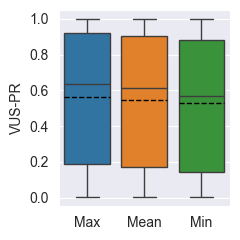

In [5]:
fig, ax = plt.subplots(1, 1, figsize=(2.5, 2.5))

df_ = load_results("HydraAD", mode="univariate").groupby("file")
sns.boxplot(
    pd.concat(
        [
            df_.max().rename(columns={"HydraAD": "Max"}),
            df_.mean().rename(columns={"HydraAD": "Mean"}),
            df_.min().rename(columns={"HydraAD": "Min"}),
        ]
    ),
    ax=ax,
    meanprops=dict(color="k", linestyle="--"),
    showmeans=True,
    meanline=True,
)

print(
    f"Mean performance if max over all runs is taken: {df_.max().mean().values[0]:.4f}"
)
print(
    f"Mean performance if mean over all runs is taken: {df_.mean().mean().values[0]:.4f}"
)
print(
    f"Mean performance if min over all runs is taken: {df_.min().mean().values[0]:.4f}"
)

ax.set_ylabel("VUS-PR")
ax.tick_params(axis="x", labelrotation=0)
fig.tight_layout()
fig.savefig("figures/fig-hydraad-variation-univariate-boxplot.png", bbox_inches="tight")

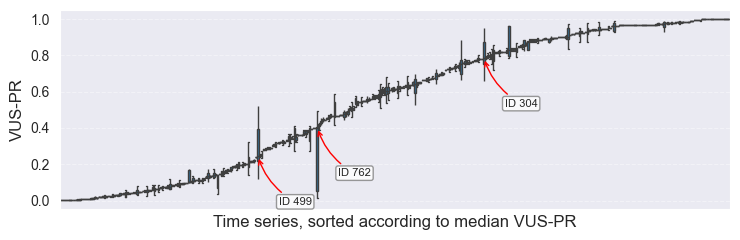

In [6]:
fig, ax = plt.subplots(1, 1, figsize=(7.5, 2.5))
_, statistics = plot_boxplot_variation(
    load_results("HydraAD", mode="univariate"), threshold=3, ax=ax
)
ax.set_title("")
fig.tight_layout()
fig.savefig("figures/fig-hydraad-variation-univariate.png", bbox_inches="tight")

In [7]:
statistics["whisker_dist"].quantile(0.95), statistics["whisker_dist"].max()

(0.09260916021966357, 0.4804475239306248)

(1680,)


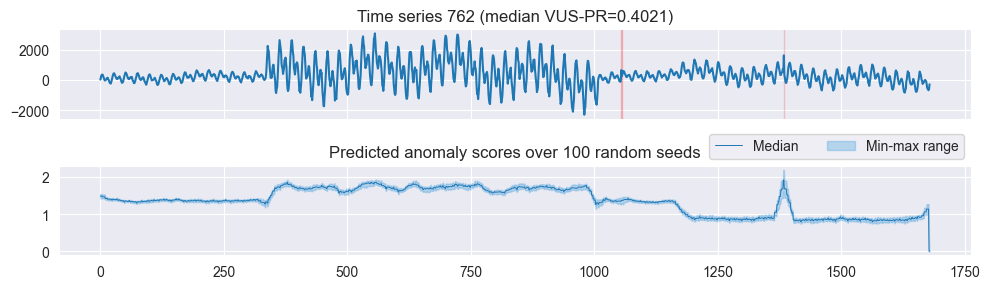

In [8]:
fig = repeated_hydraad_evaluation(
    statistics.loc[statistics["whisker_dist"].sort_values(ascending=False).index[0]]
)
fig.tight_layout()
fig.savefig("figures/fig-hydraad-variation-univariate-example.png", bbox_inches="tight")

(8184,)


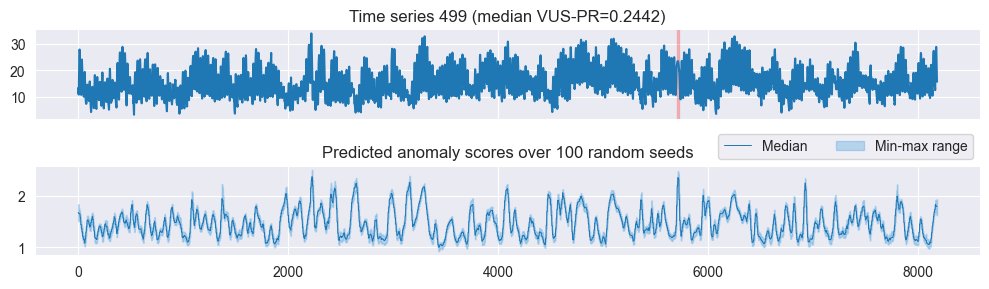

In [9]:
fig = repeated_hydraad_evaluation(
    statistics.loc[statistics["whisker_dist"].sort_values(ascending=False).index[1]]
)
fig.tight_layout()
fig.savefig(
    "figures/fig-hydraad-variation-univariate-example-2.png", bbox_inches="tight"
)

(9998,)


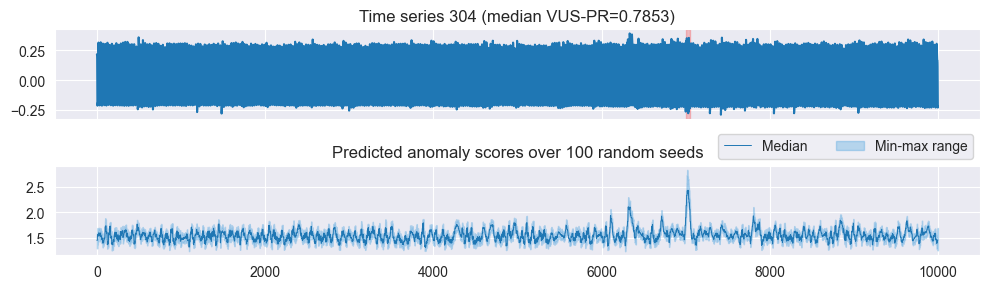

In [10]:
fig = repeated_hydraad_evaluation(
    statistics.loc[statistics["whisker_dist"].sort_values(ascending=False).index[2]]
)
fig.tight_layout()
fig.savefig(
    "figures/fig-hydraad-variation-univariate-example-3.png", bbox_inches="tight"
)

## TSB-AD-M

Mean performance if max over all runs is taken: 0.3892
Mean performance if mean over all runs is taken: 0.3800
Mean performance if min over all runs is taken: 0.3698


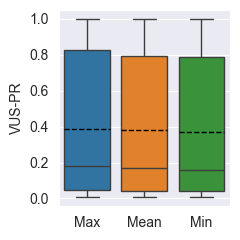

In [14]:
fig, ax = plt.subplots(1, 1, figsize=(2.5, 2.5))

df_ = load_results("HydraAD", mode="multivariate").groupby("file")
sns.boxplot(
    pd.concat(
        [
            df_.max().rename(columns={"HydraAD": "Max"}),
            df_.mean().rename(columns={"HydraAD": "Mean"}),
            df_.min().rename(columns={"HydraAD": "Min"}),
        ]
    ),
    ax=ax,
    meanprops=dict(color="k", linestyle="--"),
    showmeans=True,
    meanline=True,
)

print(
    f"Mean performance if max over all runs is taken: {df_.max().mean().values[0]:.4f}"
)
print(
    f"Mean performance if mean over all runs is taken: {df_.mean().mean().values[0]:.4f}"
)
print(
    f"Mean performance if min over all runs is taken: {df_.min().mean().values[0]:.4f}"
)

ax.set_ylabel("VUS-PR")
ax.tick_params(axis="x", labelrotation=0)
fig.tight_layout()
fig.savefig(
    "figures/fig-hydraad-variation-multivariate-boxplot.png", bbox_inches="tight"
)

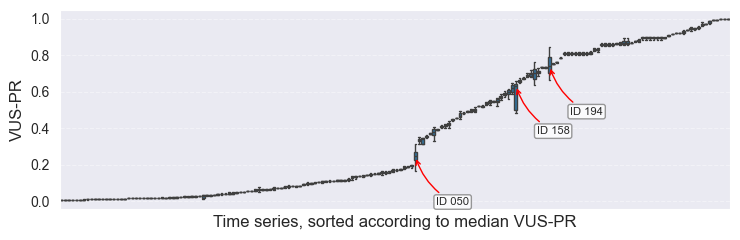

In [12]:
fig, ax = plt.subplots(1, 1, figsize=(7.5, 2.5))
_, statistics = plot_boxplot_variation(
    load_results("HydraAD", mode="multivariate"), threshold=3, ax=ax
)
ax.set_title("")
fig.tight_layout()
fig.savefig("figures/fig-hydraad-variation-multivariate.png", bbox_inches="tight")

(46649, 12)


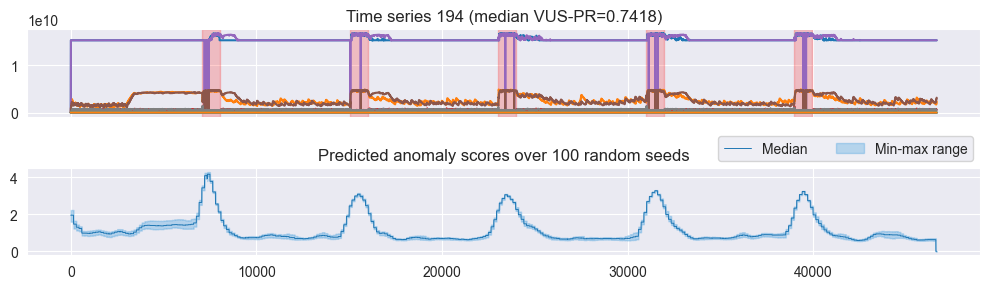

In [13]:
fig = repeated_hydraad_evaluation(
    statistics.loc[statistics["whisker_dist"].sort_values(ascending=False).index[0]]
)
fig.tight_layout()
fig.savefig(
    "figures/fig-hydraad-variation-multivariate-example.png", bbox_inches="tight"
)